<a href="https://colab.research.google.com/github/Tejaswini-2207/Teju-22/blob/main/Kernelization_in_SVM_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, classification_report

print("SVM Kernelization Experiment Started")

SVM Kernelization Experiment Started


Dataset Shape: (500, 2)
Target Shape: (500,)


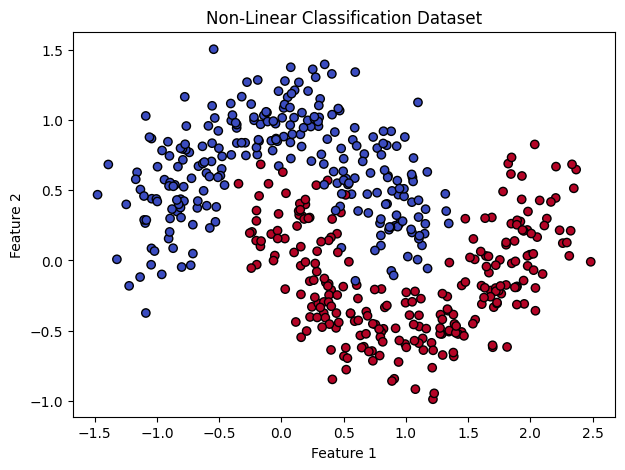

In [2]:
# Generate non-linear dataset
X, y = make_moons(
    n_samples=500,
    noise=0.20,
    random_state=42
)

# Display dataset
print("Dataset Shape:", X.shape)
print("Target Shape:", y.shape)

# Visualize dataset
plt.figure(figsize=(7, 5))

plt.scatter(
    X[:, 0],
    X[:, 1],
    c=y,
    cmap="coolwarm",
    edgecolors="black"
)

plt.title("Non-Linear Classification Dataset")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

In [3]:
# Split dataset into training and testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

# Standardize features
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("\nFeature standardization completed!")

Training samples: 400
Testing samples: 100

Feature standardization completed!


In [4]:
# Create Linear SVM model
linear_svm = make_pipeline(
    StandardScaler(),
    SVC(kernel="linear", C=1)
)

# Train model
linear_svm.fit(X_train, y_train)

# Predict
linear_predictions = linear_svm.predict(X_test)

# Evaluate
linear_accuracy = accuracy_score(
    y_test,
    linear_predictions
)

print("Linear SVM Accuracy:", linear_accuracy)

print("\nClassification Report:")
print(classification_report(y_test, linear_predictions))

Linear SVM Accuracy: 0.86

Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.84      0.86        50
           1       0.85      0.88      0.86        50

    accuracy                           0.86       100
   macro avg       0.86      0.86      0.86       100
weighted avg       0.86      0.86      0.86       100



In [5]:
# Polynomial Kernel SVM

poly_svm = make_pipeline(
    StandardScaler(),
    SVC(kernel="poly", degree=3, C=1)
)

# Train model
poly_svm.fit(X_train, y_train)

# Predict
poly_predictions = poly_svm.predict(X_test)

# Evaluate
poly_accuracy = accuracy_score(y_test, poly_predictions)

print("Polynomial SVM Accuracy:", poly_accuracy)

Polynomial SVM Accuracy: 0.85


In [6]:
# RBF Kernel SVM

rbf_svm = make_pipeline(
    StandardScaler(),
    SVC(kernel="rbf", C=1, gamma="scale")
)

# Train model
rbf_svm.fit(X_train, y_train)

# Predict
rbf_predictions = rbf_svm.predict(X_test)

# Evaluate
rbf_accuracy = accuracy_score(y_test, rbf_predictions)

print("RBF SVM Accuracy:", rbf_accuracy)

RBF SVM Accuracy: 0.99


       Kernel  Accuracy
0      Linear      0.86
1  Polynomial      0.85
2         RBF      0.99


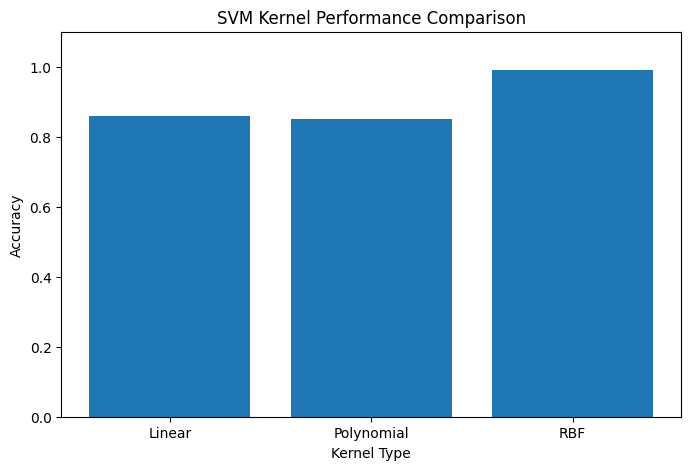

In [7]:
# Compare model performance

results = pd.DataFrame({
    "Kernel": ["Linear", "Polynomial", "RBF"],
    "Accuracy": [
        linear_accuracy,
        poly_accuracy,
        rbf_accuracy
    ]
})

print(results)

# Visualization
plt.figure(figsize=(8, 5))

plt.bar(results["Kernel"], results["Accuracy"])

plt.title("SVM Kernel Performance Comparison")
plt.xlabel("Kernel Type")
plt.ylabel("Accuracy")
plt.ylim(0, 1.1)

plt.show()

In [9]:
from matplotlib.colors import ListedColormap

# Create function to visualize decision boundaries
def plot_decision_boundary(model, X, y, title):

    x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
    y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5

    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 300),
        np.linspace(y_min, y_max, 300)
    )

    grid = np.c_[xx.ravel(), yy.ravel()]

    Z = model.predict(grid)
    Z = Z.reshape(xx.shape)

    plt.contourf(
        xx, yy, Z,
        alpha=0.3,
        cmap=ListedColormap(["#FFAAAA", "#AAAAFF"])
    )

    plt.scatter(
        X[:, 0], X[:, 1],
        c=y,
        cmap="coolwarm",
        edgecolors="black"
    )

    plt.title(title)
    plt.xlabel("Feature 1")
    plt.ylabel("Feature 2")

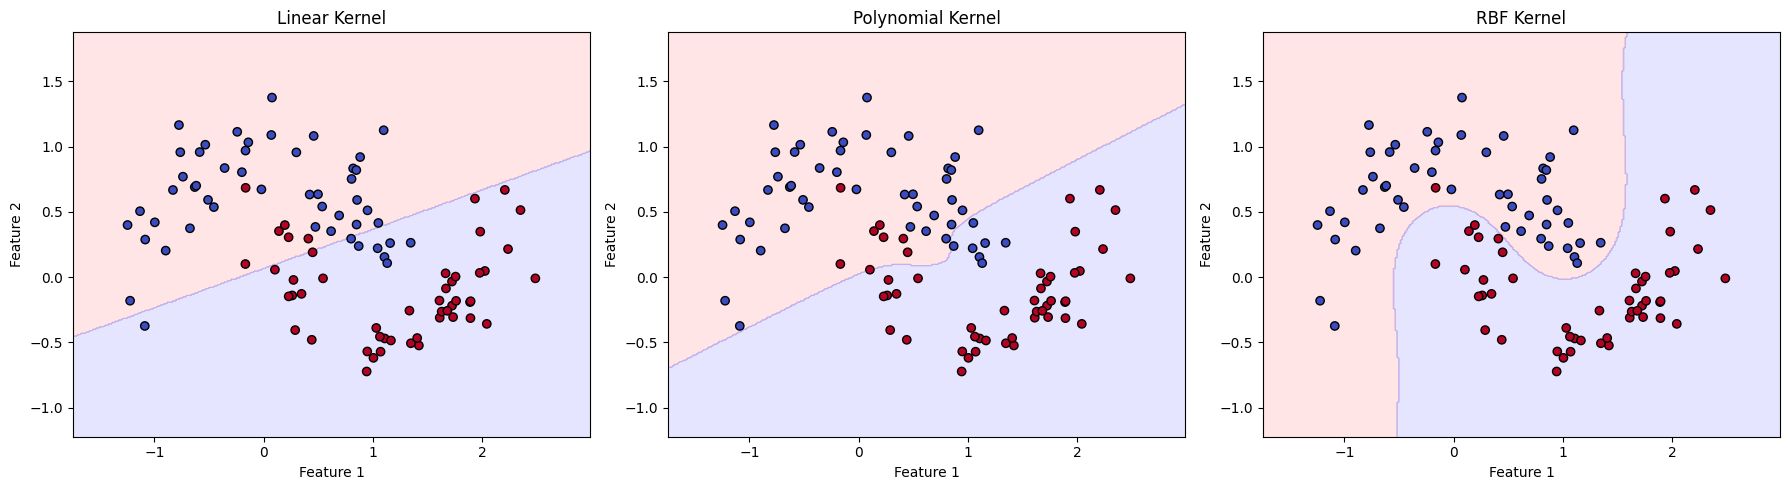

In [10]:
plt.figure(figsize=(18, 5))

plt.subplot(1, 3, 1)
plot_decision_boundary(
    linear_svm, X_test, y_test,
    "Linear Kernel"
)

plt.subplot(1, 3, 2)
plot_decision_boundary(
    poly_svm, X_test, y_test,
    "Polynomial Kernel"
)

plt.subplot(1, 3, 3)
plot_decision_boundary(
    rbf_svm, X_test, y_test,
    "RBF Kernel"
)

plt.tight_layout()
plt.show()

In [11]:
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline

# Create SVM pipeline
pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", SVC())
])

# Define parameter combinations
param_grid = [
    {
        "svm__kernel": ["linear"],
        "svm__C": [0.1, 1, 10, 100]
    },
    {
        "svm__kernel": ["poly"],
        "svm__C": [0.1, 1, 10],
        "svm__degree": [2, 3, 4]
    },
    {
        "svm__kernel": ["rbf"],
        "svm__C": [0.1, 1, 10, 100],
        "svm__gamma": ["scale", 0.1, 1]
    }
]

# Grid search
grid = GridSearchCV(
    pipeline,
    param_grid,
    cv=5,
    scoring="accuracy"
)

grid.fit(X_train, y_train)

print("Best Parameters:")
print(grid.best_params_)

print("\nBest Cross Validation Accuracy:")
print(grid.best_score_)

print("\nTest Accuracy:")
print(grid.score(X_test, y_test))

Best Parameters:
{'svm__C': 100, 'svm__gamma': 'scale', 'svm__kernel': 'rbf'}

Best Cross Validation Accuracy:
0.9775

Test Accuracy:
0.99


In [12]:
best_model = grid.best_estimator_

best_predictions = best_model.predict(X_test)

print("Best Model Classification Report:")
print(classification_report(y_test, best_predictions))

print("Best Model Accuracy:",
      accuracy_score(y_test, best_predictions))

Best Model Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.98      0.99        50
           1       0.98      1.00      0.99        50

    accuracy                           0.99       100
   macro avg       0.99      0.99      0.99       100
weighted avg       0.99      0.99      0.99       100

Best Model Accuracy: 0.99


In [13]:
import joblib

joblib.dump(best_model, "best_svm_kernel_model.pkl")

print("Best SVM model saved successfully!")

Best SVM model saved successfully!
